# Empirical Analysis of Financial Returns

This notebook studies the statistical properties of real financial returns and compares them with the assumptions of Geometric Brownian Motion.

The analysis focuses on:

- simple and logarithmic returns;
- empirical return distributions;
- skewness and kurtosis;
- normality tests;
- autocorrelation;
- volatility clustering;
- rolling volatility;
- drawdowns.

The central question is:

> How well do the assumptions of Geometric Brownian Motion describe real market data?

In [20]:
# Numerical operations, arrays, and logarithms
import numpy as np

# Labelled tables and time-series manipulation
import pandas as pd

# Static visualizations
import matplotlib.pyplot as plt

# Historical market data
import yfinance as yf

# Statistical distributions and hypothesis tests
from scipy import stats

# Autocorrelation plots for time-series analysis
from statsmodels.graphics.tsaplots import plot_acf

# Display multiple tables clearly inside notebook cells
from IPython.display import display

In [21]:
# Use one broad-market asset while developing the analysis
TICKER = "SPY"

# A long sample gives us enough observations for meaningful statistical analysis
START_DATE = "2015-01-01"

# None means that yfinance will retrieve data up to the latest available date
END_DATE = None

# Daily observations are appropriate for the first version of the project
INTERVAL = "1d"

In [22]:
# Download daily market data using explicitly adjusted prices
market_data = yf.download(
    tickers=TICKER,
    start=START_DATE,
    end=END_DATE,
    interval=INTERVAL,
    auto_adjust=True,
    actions=False,
    progress=False,
    multi_level_index=False,
)

# Stop immediately if the external data request returned no observations
if market_data.empty:
    raise ValueError(
        f"No data was downloaded for ticker {TICKER}. "
        "Check the ticker, internet connection, and date range."
    )

market_data.head()

,Close,High,Low,Open,Volume
Date,,,,,
2015-01-02,169.687866,170.885595,168.655350,170.472589,121465900
2015-01-05,166.623322,168.812251,166.317701,168.647051,169632600
2015-01-06,165.053909,167.449342,164.260931,166.928950,209151400
2015-01-07,167.110687,167.449356,165.929495,166.375536,125346700
2015-01-08,170.076065,170.290837,168.498390,168.514901,147217800


In [23]:
# Inspect the first and last observations to verify the date range and columns
display(market_data.head())
display(market_data.tail())

# Examine the structural properties of the DataFrame
print(f"Number of observations: {market_data.shape[0]}")
print(f"Number of columns: {market_data.shape[1]}")
print(f"First date: {market_data.index.min()}")
print(f"Last date: {market_data.index.max()}")
print(f"Index type: {type(market_data.index).__name__}")
print(f"Columns: {market_data.columns.tolist()}")

# Count missing values separately for each field
display(market_data.isna().sum().rename("missing_values"))

,Close,High,Low,Open,Volume
Date,,,,,
2015-01-02,169.687866,170.885595,168.655350,170.472589,121465900
2015-01-05,166.623322,168.812251,166.317701,168.647051,169632600
2015-01-06,165.053909,167.449342,164.260931,166.928950,209151400
2015-01-07,167.110687,167.449356,165.929495,166.375536,125346700
2015-01-08,170.076065,170.290837,168.498390,168.514901,147217800


,Close,High,Low,Open,Volume
Date,,,,,
2026-07-24,738.929993,743.719971,737.289978,738.510010,44782000
2026-07-27,739.090027,745.530029,735.869995,744.909973,41461200
2026-07-28,740.859985,742.789978,735.979980,739.190002,47322200
2026-07-29,729.460022,742.679993,729.099976,739.969971,70697200
2026-07-30,741.690002,742.450012,734.590027,736.049988,66725600


Number of observations: 2910
Number of columns: 5
First date: 2015-01-02 00:00:00
Last date: 2026-07-30 00:00:00
Index type: DatetimeIndex
Columns: ['Close', 'High', 'Low', 'Open', 'Volume']


Close     0
High      0
Low       0
Open      0
Volume    0
Name: missing_values, dtype: int64

In [24]:
# Keep the adjusted closing price in a DataFrame that can later hold derived variables
asset_data = (
    market_data[["Close"]]
    .rename(columns={"Close": "adjusted_close"})
    .dropna()
)

asset_data.head()

,adjusted_close
Date,
2015-01-02,169.687866
2015-01-05,166.623322
2015-01-06,165.053909
2015-01-07,167.110687
2015-01-08,170.076065


In [25]:
# Confirm that the cleaned dataset contains usable observations
assert not asset_data.empty, "The cleaned price dataset is empty."

# Time-series operations assume observations are ordered chronologically
assert asset_data.index.is_monotonic_increasing, (
    "The date index is not sorted in increasing order."
)

# Each trading date should identify no more than one daily observation
assert asset_data.index.is_unique, (
    "Duplicate trading dates were found."
)

# A conventional asset price must be strictly positive
assert asset_data["adjusted_close"].gt(0).all(), (
    "Non-positive adjusted prices were found."
)

print("Price data validation passed.")

Price data validation passed.


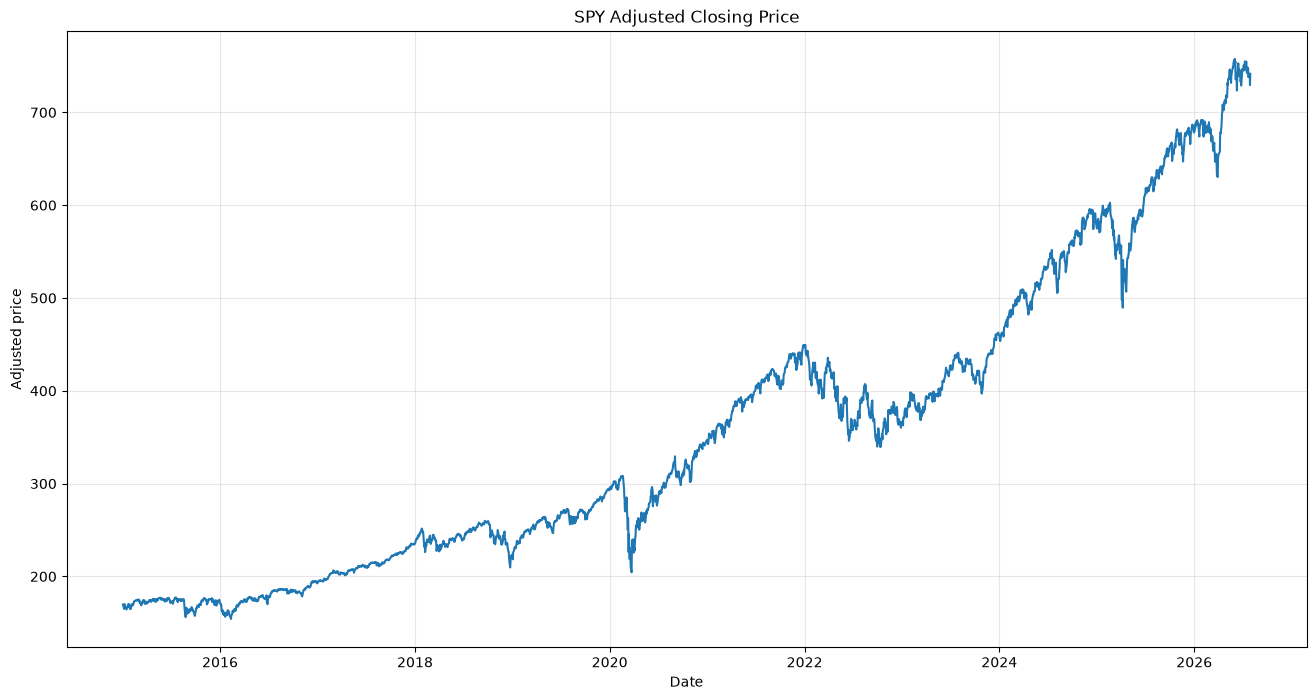

In [26]:
# Create explicit figure and axes objects for predictable plot customization
fig, ax = plt.subplots(figsize=(16, 8))

# Plot the adjusted price against its actual trading dates
ax.plot(
    asset_data.index,
    asset_data["adjusted_close"],
    linewidth=1.5,
)

# Add labels that make the figure understandable without reading the code
ax.set_title(f"{TICKER} Adjusted Closing Price")
ax.set_xlabel("Date")
ax.set_ylabel("Adjusted price")
ax.grid(alpha=0.3)

plt.show()

In [27]:
# Preserve the validated price data by working on an independent copy
returns_data = asset_data.copy()

# Compute the percentage change from each trading day to the next
returns_data["simple_return"] = (
    returns_data["adjusted_close"]
    .pct_change(fill_method=None)
)

returns_data.head()

,adjusted_close,simple_return
Date,,
2015-01-02,169.687866,NaN
2015-01-05,166.623322,-0.018060
2015-01-06,165.053909,-0.009419
2015-01-07,167.110687,0.012461
2015-01-08,170.076065,0.017745


maybe lets see how it would look like if i had to access previous row manually each time

In [28]:
# prices / prices.shift(1) - 1

# shift gives the previous element would also work

In [29]:
# Align every adjusted price with the previous trading day's price
previous_price = returns_data["adjusted_close"].shift(1)

# Compute continuously compounded returns from consecutive prices
returns_data["log_return"] = np.log(
    returns_data["adjusted_close"] / previous_price
)

returns_data.head()

,adjusted_close,simple_return,log_return
Date,,,
2015-01-02,169.687866,NaN,NaN
2015-01-05,166.623322,-0.018060,-0.018225
2015-01-06,165.053909,-0.009419,-0.009464
2015-01-07,167.110687,0.012461,0.012384
2015-01-08,170.076065,0.017745,0.017589


In [30]:
# Inspect the first rows before removing the expected initial missing return
display(returns_data.head())

# Remove rows where either return cannot be calculated
returns_data = returns_data.dropna(
    subset=["simple_return", "log_return"]
)

# Display the cleaned return dataset
returns_data.head()

,adjusted_close,simple_return,log_return
Date,,,
2015-01-02,169.687866,NaN,NaN
2015-01-05,166.623322,-0.018060,-0.018225
2015-01-06,165.053909,-0.009419,-0.009464
2015-01-07,167.110687,0.012461,0.012384
2015-01-08,170.076065,0.017745,0.017589


,adjusted_close,simple_return,log_return
Date,,,
2015-01-05,166.623322,-0.018060,-0.018225
2015-01-06,165.053909,-0.009419,-0.009464
2015-01-07,167.110687,0.012461,0.012384
2015-01-08,170.076065,0.017745,0.017589
2015-01-09,168.713135,-0.008014,-0.008046


In [31]:
# Reconstruct log returns from simple returns using the exact relationship
log_returns_from_simple = np.log1p(
    returns_data["simple_return"]
)

# Reconstruct simple returns from log returns using the inverse relationship
simple_returns_from_log = np.expm1(
    returns_data["log_return"]
)

# Measure the largest numerical discrepancy across all observations
maximum_log_difference = np.max(
    np.abs(
        returns_data["log_return"]
        - log_returns_from_simple
    )
)

maximum_simple_difference = np.max(
    np.abs(
        returns_data["simple_return"]
        - simple_returns_from_log
    )
)

print(
    "Maximum log-return reconstruction difference: "
    f"{maximum_log_difference:.3e}"
)

print(
    "Maximum simple-return reconstruction difference: "
    f"{maximum_simple_difference:.3e}"
)

Maximum log-return reconstruction difference: 0.000e+00
Maximum simple-return reconstruction difference: 6.939e-18


In [32]:
# Select a small sample so the two return definitions can be compared directly
return_comparison = returns_data[
    ["simple_return", "log_return"]
].head(10).copy()

# Add the difference between the two representations
return_comparison["difference"] = (
    return_comparison["simple_return"]
    - return_comparison["log_return"]
)

display(return_comparison)

,simple_return,log_return,difference
Date,,,
2015-01-05,-0.018060,-0.018225,0.000165
2015-01-06,-0.009419,-0.009464,0.000045
2015-01-07,0.012461,0.012384,0.000077
2015-01-08,0.017745,0.017589,0.000156
2015-01-09,-0.008014,-0.008046,0.000032
2015-01-12,-0.007834,-0.007864,0.000031
2015-01-13,-0.002812,-0.002816,0.000004
2015-01-14,-0.006037,-0.006056,0.000018
2015-01-15,-0.009160,-0.009203,0.000042


In [33]:
# Compound all daily simple returns into one total holding-period return
total_simple_return = (
    (1 + returns_data["simple_return"]).prod()
    - 1
)

# Add all daily log returns across the complete sample
total_log_return = returns_data["log_return"].sum()

# Convert the cumulative log return back into a simple return
total_return_from_logs = np.expm1(total_log_return)

# Calculate the same total return directly from the first and last prices
direct_price_return = (
    asset_data["adjusted_close"].iloc[-1]
    / asset_data["adjusted_close"].iloc[0]
    - 1
)

pd.Series({
    "compounded_simple_return": total_simple_return,
    "return_reconstructed_from_logs": total_return_from_logs,
    "direct_price_return": direct_price_return,
    "cumulative_log_return": total_log_return,
})

compounded_simple_return          3.370908
return_reconstructed_from_logs    3.370908
direct_price_return               3.370908
cumulative_log_return             1.474971
dtype: float64

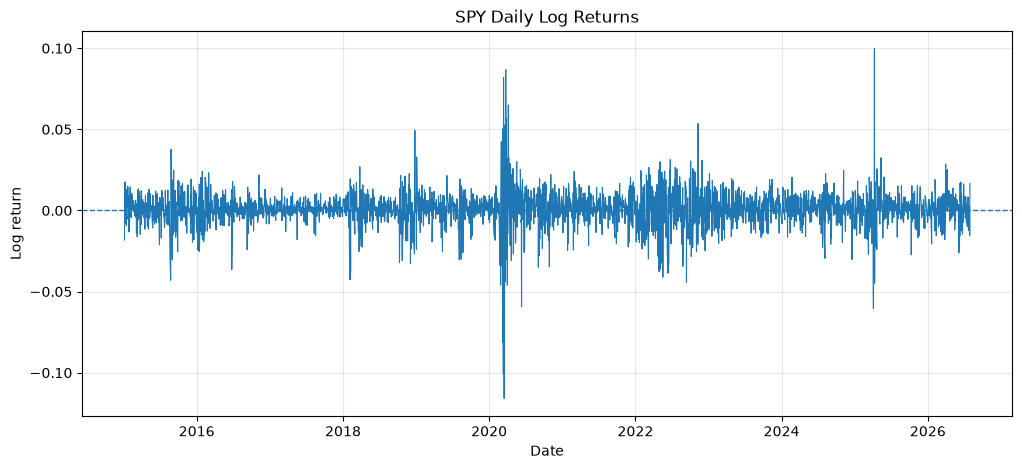

In [34]:
# Create a dedicated figure for the daily log-return process
fig, ax = plt.subplots(figsize=(12, 5))

# Plot returns against their actual trading dates
ax.plot(
    returns_data.index,
    returns_data["log_return"],
    linewidth=0.8,
)

# Add a zero-reference line to distinguish positive and negative returns
ax.axhline(
    y=0,
    linestyle="--",
    linewidth=1,
)

ax.set_title(f"{TICKER} Daily Log Returns")
ax.set_xlabel("Date")
ax.set_ylabel("Log return")
ax.grid(alpha=0.3)

plt.show()

In [35]:
# Extract the primary statistical series for clearer formulas below
daily_log_returns = returns_data["log_return"]

# Calculate location, dispersion, asymmetry, and tail-related statistics
return_summary = pd.Series({
    "number_of_observations": daily_log_returns.count(),
    "daily_mean": daily_log_returns.mean(),
    "daily_standard_deviation": daily_log_returns.std(ddof=1),
    "minimum": daily_log_returns.min(),
    "25th_percentile": daily_log_returns.quantile(0.25),
    "median": daily_log_returns.median(),
    "75th_percentile": daily_log_returns.quantile(0.75),
    "maximum": daily_log_returns.max(),
    "skewness": stats.skew(
        daily_log_returns,
        bias=False,
    ),
    "excess_kurtosis": stats.kurtosis(
        daily_log_returns,
        fisher=True,
        bias=False,
    ),
})

return_summary

number_of_observations      2909.000000
daily_mean                     0.000507
daily_standard_deviation       0.011121
minimum                       -0.115886
25th_percentile               -0.003711
median                         0.000652
75th_percentile                0.005912
maximum                        0.099863
skewness                      -0.573764
excess_kurtosis               14.445687
dtype: float64

In [36]:
# Use the conventional approximate number of equity trading days per year
TRADING_DAYS_PER_YEAR = 252

# Scale the average log return linearly through time
annualized_mean_log_return = (
    daily_log_returns.mean()
    * TRADING_DAYS_PER_YEAR
)

# Scale volatility with the square root of time
annualized_volatility = (
    daily_log_returns.std(ddof=1)
    * np.sqrt(TRADING_DAYS_PER_YEAR)
)

# Convert the annualized log-return estimate into a simple-return equivalent
annualized_simple_return_equivalent = np.expm1(
    annualized_mean_log_return
)

pd.Series({
    "annualized_mean_log_return": annualized_mean_log_return,
    "annualized_simple_return_equivalent": (
        annualized_simple_return_equivalent
    ),
    "annualized_volatility": annualized_volatility,
})

annualized_mean_log_return             0.127773
annualized_simple_return_equivalent    0.136295
annualized_volatility                  0.176548
dtype: float64

In [37]:
# One return is lost because the first price has no preceding observation
assert len(returns_data) == len(asset_data) - 1

# Both return definitions should contain only finite numerical values
assert np.isfinite(
    returns_data["simple_return"]
).all()

assert np.isfinite(
    returns_data["log_return"]
).all()

# The two definitions must satisfy their exact mathematical transformation
assert np.allclose(
    returns_data["log_return"],
    np.log1p(returns_data["simple_return"]),
)

# Compounding daily returns must reproduce the direct price change
assert np.isclose(
    total_simple_return,
    direct_price_return,
)

print("Return calculation checks passed.")

Return calculation checks passed.


## Empirical Return Distribution

Geometric Brownian Motion assumes that log returns over a fixed time interval are normally distributed.

This section compares the empirical distribution of daily log returns with a normal distribution having the same sample mean and standard deviation.

The comparison focuses on:

- the central shape of the distribution;
- asymmetry;
- tail thickness;
- extreme-return frequency;
- formal evidence against normality.

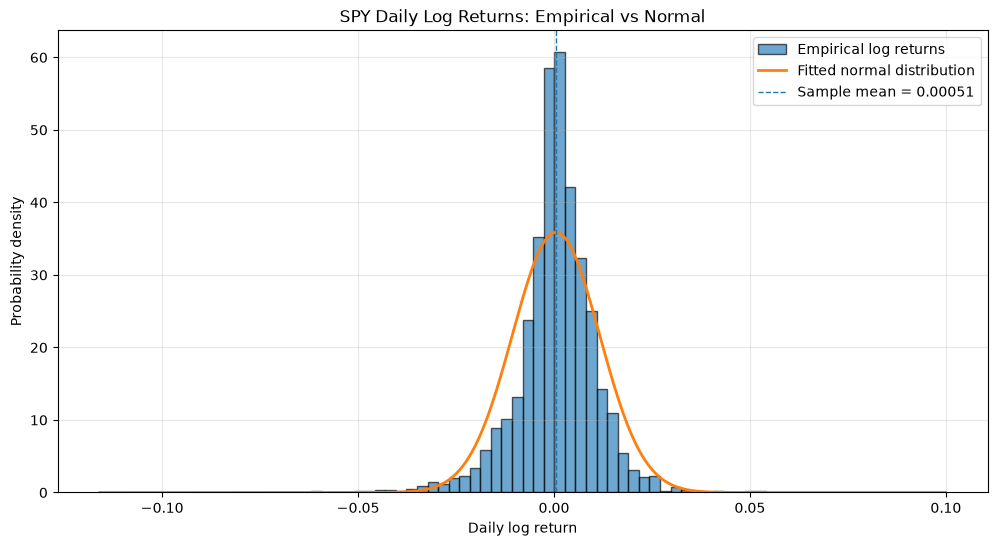

In [38]:
# Estimate the mean and standard deviation used by the fitted normal benchmark
sample_mean = daily_log_returns.mean()
sample_std = daily_log_returns.std(ddof=1)

# Create a smooth horizontal grid covering the observed return range
return_grid = np.linspace(
    daily_log_returns.min(),
    daily_log_returns.max(),
    1_000,
)

# Evaluate the fitted normal probability density at every grid point
normal_density = stats.norm.pdf(
    return_grid,
    loc=sample_mean,
    scale=sample_std,
)

# Create the empirical-distribution figure
fig, ax = plt.subplots(figsize=(12, 6))

# Plot the histogram as a density so it can be compared with a probability-density curve
ax.hist(
    daily_log_returns,
    bins=80,
    density=True,
    alpha=0.65,
    edgecolor="black",
    label="Empirical log returns",
)

# Overlay the normal distribution with matching sample mean and standard deviation
ax.plot(
    return_grid,
    normal_density,
    linewidth=2,
    label="Fitted normal distribution",
)

# Mark the empirical mean as a reference point
ax.axvline(
    sample_mean,
    linestyle="--",
    linewidth=1,
    label=f"Sample mean = {sample_mean:.5f}",
)

ax.set_title(f"{TICKER} Daily Log Returns: Empirical vs Normal")
ax.set_xlabel("Daily log return")
ax.set_ylabel("Probability density")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

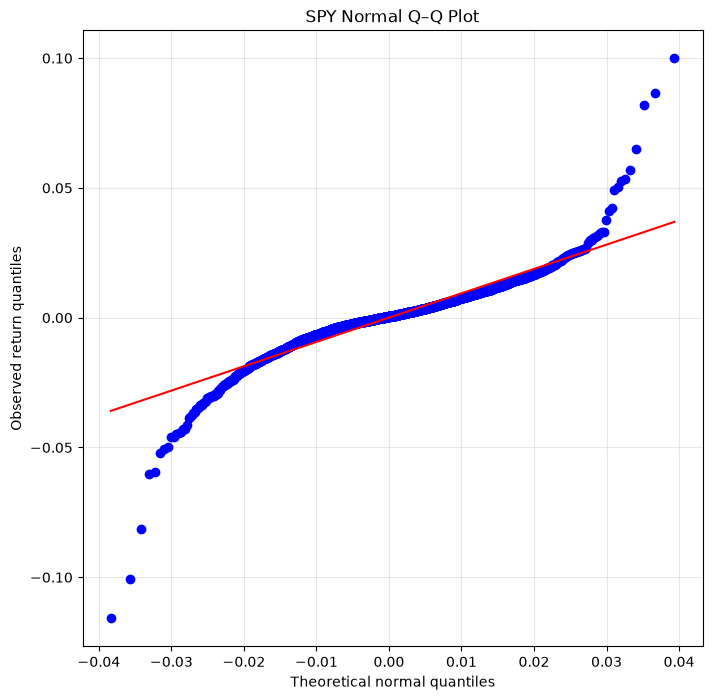

In [39]:
# Create a quantile–quantile plot comparing empirical returns with normal quantiles
fig, ax = plt.subplots(figsize=(8, 8))

stats.probplot(
    daily_log_returns,
    dist="norm",
    sparams=(sample_mean, sample_std),
    plot=ax,
)

ax.set_title(f"{TICKER} Normal Q–Q Plot")
ax.set_xlabel("Theoretical normal quantiles")
ax.set_ylabel("Observed return quantiles")
ax.grid(alpha=0.3)

plt.show()

In [41]:
# Select probabilities that emphasize both the center and the distribution tails
quantile_probabilities = np.array([
    0.001,
    0.01,
    0.05,
    0.25,
    0.50,
    0.75,
    0.95,
    0.99,
    0.999,
])

# Calculate quantiles directly from the observed return sample
empirical_quantiles = daily_log_returns.quantile(
    quantile_probabilities
).to_numpy()

# Calculate the matching quantiles under the fitted normal distribution
normal_quantiles = stats.norm.ppf(
    quantile_probabilities,
    loc=sample_mean,
    scale=sample_std,
)

# Place the comparison in a labelled table
quantile_comparison = pd.DataFrame({
    "probability": quantile_probabilities,
    "empirical_quantile": empirical_quantiles,
    "normal_quantile": normal_quantiles,
})

# Measure how far each empirical quantile lies from its normal benchmark
quantile_comparison["empirical_minus_normal"] = (
    quantile_comparison["empirical_quantile"]
    - quantile_comparison["normal_quantile"]
)

quantile_comparison

,probability,empirical_quantile,normal_quantile,empirical_minus_normal
0,0.001,-0.062257,-0.033861,-0.028396
1,0.010,-0.032068,-0.025365,-0.006702
2,0.050,-0.016707,-0.017786,0.001079
3,0.250,-0.003711,-0.006994,0.003283
4,0.500,0.000652,0.000507,0.000145
5,0.750,0.005912,0.008008,-0.002096
6,0.950,0.015463,0.018800,-0.003337
7,0.990,0.025829,0.026379,-0.000550
8,0.999,0.066573,0.034875,0.031698
